# Wav2Vec2: компонентная graduality для base и zh-cn

Сравниваются `facebook/wav2vec2-base` и `jonatasgrosman/wav2vec2-large-xlsr-53-chinese-zh-cn` на общей популяции уникальных слогов. Gold-компоненты `initial/final/tone` берутся только из нового evaluation registry. Численные DIMSIM distances не загружаются и не участвуют ни в отборе, ни в метриках, ни в bootstrap.

Два заранее заданных блока:

1. якорный порядок Q для девяти компонентных переходов и парная разность zh-cn − base;
2. cosine-распределения семи масок, edge gaps, основной контраст `D = mean(110) - mean(000)` и парная `delta D`.

Bootstrap здесь оценивает устойчивость к составу набора слогов. Он не переносит выводы на новых дикторов, записи, checkpoints или seeds обучения. Сырые cosine между моделями с разной геометрией не следует трактовать как непосредственно калиброванную общую шкалу.

In [1]:
from pathlib import Path
import hashlib
import json
import pickle
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_project_root(start=None):
    current = (Path.cwd() if start is None else Path(start)).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "src" / "phonetics").is_dir():
            return candidate
        child = candidate / "project"
        if (child / "src" / "phonetics").is_dir():
            return child
    raise FileNotFoundError("Could not find project root from current path")


PROJECT_ROOT = find_project_root()
BASE_ROOT = PROJECT_ROOT / "datasets" / "pinyin-embeddings" / "duyu-chinese-lessons-base-v1"
ZH_CN_ROOT = PROJECT_ROOT / "datasets" / "pinyin-embeddings" / "duyu-chinese-lessons-zh-cn-v1"
EXPECTED_EMBEDDING_MANIFEST_SHA256 = {
    "base": "2385f02aec4f5842cdda5fa4ffdb6245732eaf8c1bc20eb0fb078f66a0f413d3",
    "zh-cn": "25aef7ef70ec8687dda32afa92887130cd815d835f7b4ff6b9344822eb412d11",
}
EXPECTED_MODELS = {
    "base": "facebook/wav2vec2-base",
    "zh-cn": "jonatasgrosman/wav2vec2-large-xlsr-53-chinese-zh-cn",
}
EXPECTED_EXTRACTION = {"layer": -1, "pooling": "mean_all", "padding": "none",
                       "sample_rate": 16000, "mono": True, "dtype": "float32"}
REQUIRED_EMBEDDING_FILES = ("config.json", "sound_inventory.jsonl",
                            "pinyin_embeddings.pkl", "reports/inference.json")

# Пересозданный evaluation bundle: ID и hash закреплены явно.
EVALUATION_ROOT = PROJECT_ROOT / "datasets" / "evaluations" / "duyu-chinese-lessons-zh-cn-v1"
EXPECTED_EVALUATION_MANIFEST_SHA256 = "ee03ffaa7cc0d914a0f2ace349f7a3fa2e042891bd30f6a7353a306a55471b20"

BOOTSTRAP_SEED = 20261024
BOOTSTRAP_REPEATS = 1000
EXPORT_RESULTS = False
EXPORT_ROOT = PROJECT_ROOT / "outputs" / "wav2vec2-graduality"

MODEL_ORDER = ("base", "zh-cn")
MASK_ORDER = ("000", "001", "010", "011", "100", "101", "110")
SECONDARY_MASKS = ("000", "001", "100", "101")
EDGE_SPECS = (
    ("initial", "000", "100"), ("initial", "001", "101"), ("initial", "010", "110"),
    ("final", "000", "010"), ("final", "001", "011"), ("final", "100", "110"),
    ("tone", "000", "001"), ("tone", "010", "011"), ("tone", "100", "101"),
)
SECONDARY_EDGE_KEYS = (("tone", "000", "001"), ("initial", "000", "100"),
                       ("initial", "001", "101"), ("tone", "100", "101"))
PAIRING_POLICY = "nonzero_nonzero"
Q_AUTHOR_GUIDE = 0.80
DELTA_Q_AUTHOR_GUIDE = 0.05


## Строгая загрузка и provenance

Загрузчик проверяет manifest и все записанные payload hashes, удерживает пути внутри корня bundle, сверяет metadata, inventory, inference и конфигурацию модели. Pickle читается только из двух явно заданных доверенных локальных bundles; при несовместимости pickle между версиями NumPy следует использовать совместимое окружение, а не менять артефакт или устанавливать пакеты из notebook.

In [2]:
def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def read_json(path):
    with path.open("r", encoding="utf-8") as stream:
        return json.load(stream)


def read_jsonl(path):
    rows = []
    with path.open("r", encoding="utf-8") as stream:
        for line_no, line in enumerate(stream, 1):
            if line.strip():
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError as exc:
                    raise ValueError(f"Invalid JSONL {path}:{line_no}: {exc}") from exc
    return rows


def contained_path(root, relative):
    root = root.resolve()
    candidate = (root / relative).resolve()
    if candidate != root and root not in candidate.parents:
        raise ValueError(f"Artifact escapes bundle root: {relative!r}")
    return candidate


def validate_artifacts(root, manifest):
    artifacts = manifest.get("artifacts")
    if not isinstance(artifacts, dict) or not artifacts:
        raise ValueError(f"Missing artifacts map in {root / 'manifest.json'}")
    verified = {}
    for relative, expected in sorted(artifacts.items()):
        path = contained_path(root, relative)
        if not path.is_file():
            raise FileNotFoundError(path)
        actual = sha256_file(path)
        if actual != expected:
            raise ValueError(f"SHA-256 mismatch for {path}: {actual} != {expected}")
        verified[relative] = actual
    return verified


def comparable_model_config(value):
    if isinstance(value, str):
        return value
    if isinstance(value, dict):
        return {k: comparable_model_config(v) for k, v in value.items() if k != "backend"}
    if isinstance(value, list):
        return [comparable_model_config(v) for v in value]
    return value


def model_identifier(value):
    if isinstance(value, str):
        return value
    if isinstance(value, dict):
        for key in ("id", "model_id", "name", "pretrained_model_name_or_path"):
            if isinstance(value.get(key), str):
                return value[key]
    return None


def load_embedding_bundle(name, root):
    root = Path(root).resolve()
    manifest_path = root / "manifest.json"
    expected_manifest_hash = EXPECTED_EMBEDDING_MANIFEST_SHA256[name]
    actual_manifest_hash = sha256_file(manifest_path)
    if actual_manifest_hash != expected_manifest_hash:
        raise ValueError(f"Unexpected {name} manifest SHA-256: {actual_manifest_hash}")
    manifest = read_json(manifest_path)
    if manifest.get("bundle_type") != "acoustic_embeddings" or manifest.get("schema_version") != 1:
        raise ValueError(f"Unsupported embedding manifest contract for {name}")
    verified = validate_artifacts(root, manifest)
    for relative in REQUIRED_EMBEDDING_FILES:
        path = contained_path(root, relative)
        if not path.is_file() or relative not in manifest["artifacts"]:
            raise ValueError(f"Required verified embedding artifact is missing: {relative}")
    config = read_json(root / "config.json")
    inference = read_json(root / "reports/inference.json")
    inventory = read_jsonl(root / "sound_inventory.jsonl")
    labels = [row.get("label") for row in inventory]
    if any(not isinstance(x, str) or not x for x in labels) or len(labels) != len(set(labels)):
        raise ValueError(f"Invalid or duplicate inventory labels for {name}")
    inventory_hash = sha256_file(root / "sound_inventory.jsonl")
    if manifest.get("inventory_sha256") != inventory_hash:
        raise ValueError(f"inventory_sha256 mismatch for {name}")
    if inference.get("errors", 0) != 0:
        raise ValueError(f"Inference report contains errors for {name}: {inference.get('errors')}")
    manifest_model = manifest.get("model")
    config_model = config.get("model")
    if comparable_model_config(manifest_model) != comparable_model_config(config_model):
        raise ValueError(f"Manifest/config model mismatch for {name}")
    if model_identifier(manifest_model) != EXPECTED_MODELS[name]:
        raise ValueError(f"Unexpected model id for {name}: {model_identifier(manifest_model)!r}")
    if not isinstance(manifest_model, dict) or not isinstance(config_model, dict):
        raise ValueError(f"Model configuration must be an object for {name}")
    for field, expected in EXPECTED_EXTRACTION.items():
        observed = config_model.get(field, manifest_model.get(field))
        if observed != expected:
            raise ValueError(f"Unexpected extraction setting {name}/{field}: {observed!r} != {expected!r}")
    # Trusted local pickle produced by acoustic_bundle.py.
    with (root / "pinyin_embeddings.pkl").open("rb") as stream:
        raw_vectors = pickle.load(stream)
    if not isinstance(raw_vectors, dict) or set(raw_vectors) != set(labels):
        raise ValueError(f"Embedding labels do not exactly match inventory for {name}")
    vectors = {}
    dimensions = set()
    for label in labels:
        vector = np.asarray(raw_vectors[label])
        if vector.ndim != 1 or not np.issubdtype(vector.dtype, np.number):
            raise ValueError(f"Vector for {name}/{label} is not numeric 1-D")
        vector = vector.astype(np.float64, copy=False)
        if not np.isfinite(vector).all() or np.linalg.norm(vector) == 0:
            raise ValueError(f"Vector for {name}/{label} is non-finite or zero")
        dimensions.add(vector.size)
        vectors[label] = vector
    if len(dimensions) != 1:
        raise ValueError(f"Inconsistent dimensions for {name}: {sorted(dimensions)}")
    dimension = dimensions.pop()
    if manifest.get("count") != len(vectors) or manifest.get("dimension") != dimension:
        raise ValueError(f"Manifest count/dimension mismatch for {name}")
    return {"name": name, "root": root, "manifest": manifest, "config": config,
            "inference": inference, "inventory": inventory, "vectors": vectors,
            "manifest_sha256": actual_manifest_hash, "artifact_sha256": verified,
            "inventory_sha256": inventory_hash, "dimension": dimension}


def require_evaluation_settings():
    if EVALUATION_ROOT is None or EXPECTED_EVALUATION_MANIFEST_SHA256 is None:
        raise RuntimeError(
            "Set EVALUATION_ROOT and EXPECTED_EVALUATION_MANIFEST_SHA256 to the newly "
            "rebuilt evaluation bundle before loading data; no old/latest fallback is allowed."
        )
    expected = str(EXPECTED_EVALUATION_MANIFEST_SHA256)
    if len(expected) != 64 or any(c not in "0123456789abcdef" for c in expected.lower()):
        raise ValueError("EXPECTED_EVALUATION_MANIFEST_SHA256 must be a 64-digit hex digest")
    return Path(EVALUATION_ROOT).resolve(), expected.lower()


In [3]:
REQUIRED_EVALUATION_FILES = (
    "config.json", "coverage.json", "sentences.jsonl", "occurrences.jsonl", "groups.jsonl",
    "pairs/contextual.jsonl", "pairs/character_pinyin.jsonl", "pairs/syllable.jsonl",
)


def load_evaluation_bundle():
    root, expected_hash = require_evaluation_settings()
    manifest_path = root / "manifest.json"
    actual_hash = sha256_file(manifest_path)
    if actual_hash != expected_hash:
        raise ValueError(f"Unexpected evaluation manifest SHA-256: {actual_hash}")
    manifest = read_json(manifest_path)
    if manifest.get("schema_version") != 2:
        raise ValueError(f"Unsupported evaluation schema_version: {manifest.get('schema_version')!r}")
    if manifest.get("pairing_policy") != PAIRING_POLICY:
        raise ValueError(f"Unsupported pairing_policy: {manifest.get('pairing_policy')!r}")
    verified = validate_artifacts(root, manifest)
    for relative in REQUIRED_EVALUATION_FILES:
        path = contained_path(root, relative)
        if not path.is_file() or relative not in manifest["artifacts"]:
            raise ValueError(f"Required verified evaluation artifact is missing: {relative}")
    config = read_json(root / "config.json")
    coverage = read_json(root / "coverage.json")
    identity_fields = ("schema_version", "evaluation_id", "pairing_policy")
    for field in identity_fields:
        if config.get(field) != manifest.get(field):
            raise ValueError(f"Evaluation config/manifest mismatch: {field}")
    groups = read_jsonl(root / "groups.jsonl")
    syllable_pairs = read_jsonl(root / "pairs/syllable.jsonl")
    return {"root": root, "manifest": manifest, "config": config, "coverage": coverage,
            "groups": groups, "syllable_pairs": syllable_pairs,
            "manifest_sha256": actual_hash, "artifact_sha256": verified}


def normalized_component(value, field, label, allow_empty=False, coerce_string=False):
    if value is None:
        raise ValueError(f"Missing {field} for {label}")
    if not isinstance(value, str):
        if coerce_string:
            value = str(value)
        else:
            raise ValueError(f"{field} must be a string for {label}")
    value = value.strip()
    if not value and not allow_empty:
        raise ValueError(f"Empty {field} for {label}")
    return value


def prepare_population(evaluation, bundles):
    groups = evaluation["groups"]
    ids = [row.get("group_id") for row in groups]
    if any(not isinstance(x, str) or not x for x in ids) or len(ids) != len(set(ids)):
        raise ValueError("Invalid or duplicate group_id values")
    syllable_rows = [row for row in groups if row.get("group_kind") == "syllable"]
    labels = [row.get("pinyin") for row in syllable_rows]
    if any(not isinstance(x, str) or not x.strip() for x in labels):
        raise ValueError("Every syllable group must have a non-empty pinyin string")
    if len(labels) != len(set(labels)):
        raise ValueError("Duplicate pinyin labels in syllable groups")
    eligible = []
    excluded = []
    for row in syllable_rows:
        label = row["pinyin"].strip()
        initial = normalized_component(row.get("initial"), "initial", label, allow_empty=True)
        final = normalized_component(row.get("final"), "final", label)
        tone = normalized_component(row.get("tone"), "tone", label, coerce_string=True)
        if initial == "":
            excluded.append({"group_id": row["group_id"], "pinyin": label, "reason": "zero_initial"})
            continue
        eligible.append({"group_id": row["group_id"], "pinyin": label,
                         "initial": initial, "final": final, "tone": tone})
    eligible.sort(key=lambda row: row["group_id"])
    triples = [(row["initial"], row["final"], row["tone"]) for row in eligible]
    if len(triples) != len(set(triples)):
        duplicates = pd.DataFrame(eligible).loc[pd.Series(triples).duplicated(keep=False)].to_dict("records")
        raise ValueError(f"Distinct eligible labels share component triples (off-diagonal 111): {duplicates[:20]}")
    required = {row["pinyin"] for row in eligible}
    missing = {name: sorted(required - set(bundle["vectors"])) for name, bundle in bundles.items()}
    missing = {name: values for name, values in missing.items() if values}
    if missing:
        raise ValueError(f"Eligible syllables missing from embeddings; no silent intersection: {missing}")
    group_id_to_index = {row["group_id"]: i for i, row in enumerate(eligible)}
    validate_registered_syllable_pairs(evaluation["syllable_pairs"], eligible, group_id_to_index)
    acoustic_union = set().union(*(set(bundle["vectors"]) for bundle in bundles.values()))
    coverage = {
        "evaluation_groups_all": len(groups), "evaluation_syllable_groups": len(syllable_rows),
        "eligible_syllables": len(eligible), "excluded_zero_initial": len(excluded),
        "stored_syllable_pairs": len(evaluation["syllable_pairs"]),
        "full_population_pairs": len(eligible) * (len(eligible) - 1) // 2,
        "acoustic_union_labels": len(acoustic_union),
    }
    for name, bundle in bundles.items():
        coverage[f"{name}_acoustic_labels"] = len(bundle["vectors"])
        coverage[f"{name}_acoustic_extra"] = len(set(bundle["vectors"]) - required)
    contracts = {}
    for source_name, source in (("evaluation_manifest", evaluation["manifest"]),
                                ("evaluation_config", evaluation["config"]),
                                ("evaluation_coverage", evaluation["coverage"])):
        contracts[source_name] = {k: source.get(k) for k in
            ("data_contract", "pinyin_contract", "component_contract") if k in source}
    for name, bundle in bundles.items():
        contracts[f"{name}_manifest"] = {k: bundle["manifest"].get(k) for k in
            ("data_contract", "pinyin_contract", "component_contract") if k in bundle["manifest"]}
    contract_flags = []
    for key in ("data_contract", "pinyin_contract", "component_contract"):
        observed = {src: vals[key] for src, vals in contracts.items() if key in vals}
        if len({json.dumps(v, sort_keys=True) for v in observed.values()}) > 1:
            status = ("mismatch_review_required" if key in ("pinyin_contract", "component_contract")
                      else "different_domain_contracts_recorded")
            contract_flags.append({"field": key, "values": observed, "status": status})
    if not any("pinyin_contract" in values for source, values in contracts.items()
               if source.startswith("evaluation_")):
        contract_flags.append({"field": "pinyin_contract", "values": {},
                               "status": "absent_in_evaluation_recorded_limitation"})
    mismatches = [flag for flag in contract_flags if flag["status"] == "mismatch_review_required"]
    if mismatches:
        raise ValueError(f"Explicit contract mismatch requires review before analysis: {mismatches}")
    return eligible, excluded, coverage, contracts, contract_flags


def validate_registered_syllable_pairs(rows, eligible, group_id_to_index):
    required = ("pair_id", "left_id", "right_id", "left_pinyin", "right_pinyin",
                "equal_initial", "equal_final", "equal_tone", "overlap_mask",
                "left_zero_initial", "right_zero_initial", "no_zero_initial_diagnostic")
    seen_pair_ids, seen_pairs = set(), set()
    metadata = {row["group_id"]: row for row in eligible}
    for row_no, row in enumerate(rows, 1):
        if not isinstance(row, dict):
            raise ValueError(f"Syllable pair row {row_no} must be an object")
        missing = [field for field in required if field not in row]
        if missing:
            raise ValueError(f"Syllable pair row {row_no} is missing required fields: {missing}")
        pair_id, left, right = row["pair_id"], row["left_id"], row["right_id"]
        if not isinstance(left, str) or not isinstance(right, str):
            raise ValueError(f"Stored syllable pair endpoints must be strings at row {row_no}")
        if left not in group_id_to_index or right not in group_id_to_index:
            raise ValueError(f"Stored syllable pair references an ineligible/unknown group at row {row_no}")
        if left >= right:
            raise ValueError(f"Stored syllable pair is not canonical left_id < right_id at row {row_no}")
        pair_key = (left, right)
        if pair_key in seen_pairs:
            raise ValueError(f"Duplicate stored syllable pair at row {row_no}")
        expected_pair_id = hashlib.sha256(json.dumps(
            [left, right], ensure_ascii=False, separators=(",", ":")
        ).encode("utf-8")).hexdigest()
        if (not isinstance(pair_id, str) or len(pair_id) != 64 or
                any(char not in "0123456789abcdef" for char in pair_id) or
                pair_id != expected_pair_id):
            raise ValueError(f"Invalid canonical pair_id at syllable pair row {row_no}")
        if pair_id in seen_pair_ids:
            raise ValueError(f"Duplicate syllable pair_id: {pair_id!r}")
        left_meta, right_meta = metadata[left], metadata[right]
        expected = {
            "left_pinyin": left_meta["pinyin"],
            "right_pinyin": right_meta["pinyin"],
            "equal_initial": left_meta["initial"] == right_meta["initial"],
            "equal_final": left_meta["final"] == right_meta["final"],
            "equal_tone": left_meta["tone"] == right_meta["tone"],
            "left_zero_initial": left_meta["initial"] == "",
            "right_zero_initial": right_meta["initial"] == "",
            "no_zero_initial_diagnostic": (left_meta["initial"] != "" and
                                           right_meta["initial"] != ""),
        }
        expected["overlap_mask"] = "".join(
            "1" if expected[field] else "0"
            for field in ("equal_initial", "equal_final", "equal_tone")
        )
        for field in ("equal_initial", "equal_final", "equal_tone",
                      "left_zero_initial", "right_zero_initial",
                      "no_zero_initial_diagnostic"):
            if type(row[field]) is not bool:
                raise ValueError(f"{field} must be bool at syllable pair row {row_no}")
        for field, expected_value in expected.items():
            if row[field] != expected_value:
                raise ValueError(f"Recorded {field} mismatch at syllable pair row {row_no}")
        seen_pairs.add(pair_key)
        seen_pair_ids.add(pair_id)


## Загрузка, join и coverage

Эта ячейка намеренно падает до чтения evaluation при незаполненных placeholders. Она также требует одинаковые inventory/audio hashes двух acoustic bundles, но допускает разные размерности векторов. Таблица coverage явно различает полный acoustic inventory, все registry groups, eligible population, исключённые zero-initial группы, stored pair plan и полный набор пар, который строится ниже.

In [4]:
evaluation_root, evaluation_manifest_hash = require_evaluation_settings()
bundles = {name: load_embedding_bundle(name, root) for name, root in
           (("base", BASE_ROOT), ("zh-cn", ZH_CN_ROOT))}

if bundles["base"]["inventory_sha256"] != bundles["zh-cn"]["inventory_sha256"]:
    raise ValueError("The two embedding bundles do not use the identical sound inventory payload")

base_inventory = {row["label"]: row for row in bundles["base"]["inventory"]}
zh_inventory = {row["label"]: row for row in bundles["zh-cn"]["inventory"]}
if set(base_inventory) != set(zh_inventory):
    raise ValueError("Acoustic inventory labels differ between models")
for label in sorted(base_inventory):
    for field in ("sha256", "relative_path", "sample_rate", "channels", "frames"):
        if base_inventory[label].get(field) != zh_inventory[label].get(field):
            raise ValueError(f"Acoustic inventory mismatch for {label}/{field}")

evaluation = load_evaluation_bundle()
population, excluded_groups, coverage, contracts, contract_flags = prepare_population(evaluation, bundles)
coverage_table = pd.DataFrame([coverage])
provenance_table = pd.DataFrame([
    {"model": name, "model_id": model_identifier(bundle["manifest"].get("model")),
     "dimension": bundle["dimension"], "manifest_sha256": bundle["manifest_sha256"],
     "inventory_sha256": bundle["inventory_sha256"], "layer": bundle["config"]["model"].get("layer"),
     "pooling": bundle["config"]["model"].get("pooling"), "padding": bundle["config"]["model"].get("padding"),
     "sample_rate": bundle["config"]["model"].get("sample_rate"), "mono": bundle["config"]["model"].get("mono")}
    for name, bundle in bundles.items()
])
evaluation_provenance_table = pd.DataFrame([{
    "manifest_sha256": evaluation["manifest_sha256"],
    "schema_version": evaluation["manifest"].get("schema_version"),
    "evaluation_id": evaluation["manifest"].get("evaluation_id"),
    "pairing_policy": evaluation["manifest"].get("pairing_policy"),
    "source_experiment": evaluation["manifest"].get("source_experiment"),
    "metric": evaluation["manifest"].get("metric"),
}])
display(provenance_table, evaluation_provenance_table, coverage_table, pd.DataFrame(contract_flags))


,model,model_id,dimension,manifest_sha256,inventory_sha256,layer,pooling,padding,sample_rate,mono
0,base,facebook/wav2vec2-base,768,2385f02aec4f5842cdda5fa4ffdb6245732eaf8c1bc20e...,f90172e72c6792d1f65eeab8fae8e164915a648fb7b480...,-1,mean_all,legacy_one_second,16000,True
1,zh-cn,jonatasgrosman/wav2vec2-large-xlsr-53-chinese-...,1024,25aef7ef70ec8687dda32afa92887130cd815d835f7b4f...,f90172e72c6792d1f65eeab8fae8e164915a648fb7b480...,-1,mean_all,legacy_one_second,16000,True


,manifest_sha256,schema_version,evaluation_id,pairing_policy,source_experiment,metric
0,ee03ffaa7cc0d914a0f2ace349f7a3fa2e042891bd30f6...,2,duyu-chinese-lessons-zh-cn-v1,nonzero_nonzero,{'experiment_id': 'duyu-chinese-lessons-zh-cn-...,"{'api': 'dimsim.get_distance([left], [right], ..."


,evaluation_groups_all,evaluation_syllable_groups,eligible_syllables,excluded_zero_initial,stored_syllable_pairs,full_population_pairs,acoustic_union_labels,base_acoustic_labels,base_acoustic_extra,zh-cn_acoustic_labels,zh-cn_acoustic_extra
0,4717,1033,931,102,432915,432915,1188,1188,257,1188,257


,field,values,status
0,pinyin_contract,{},absent_in_evaluation_recorded_limitation


In [5]:
def build_analysis_arrays(population, bundles):
    labels = [row["pinyin"] for row in population]
    components = np.asarray([[row["initial"], row["final"], row["tone"]] for row in population], dtype=object)
    n = len(labels)
    pair_i, pair_j = np.triu_indices(n, k=1)
    masks = np.asarray(["".join(bits) for bits in
        np.where(components[pair_i] == components[pair_j], "1", "0")])
    if np.any(masks == "111"):
        bad = [(labels[i], labels[j]) for i, j in zip(pair_i[masks == "111"], pair_j[masks == "111"])]
        raise ValueError(f"Off-diagonal mask 111 is forbidden: {bad[:20]}")
    unknown_masks = sorted(set(masks) - set(MASK_ORDER))
    if unknown_masks:
        raise ValueError(f"Unexpected masks: {unknown_masks}")
    cosine = {}
    matrices = {}
    for name in MODEL_ORDER:
        matrix = np.stack([bundles[name]["vectors"][label] for label in labels])
        matrix = matrix / np.linalg.norm(matrix, axis=1, keepdims=True)
        sim = matrix @ matrix.T
        if not np.isfinite(sim).all() or not np.allclose(sim, sim.T, atol=1e-10):
            raise ValueError(f"Invalid cosine matrix for {name}")
        if np.min(sim) < -1 - 1e-8 or np.max(sim) > 1 + 1e-8:
            raise ValueError(f"Cosine outside [-1, 1] tolerance for {name}")
        matrices[name] = sim
        cosine[name] = sim[pair_i, pair_j]
    expected_pairs = n * (n - 1) // 2
    if len(pair_i) != expected_pairs or len(set(zip(pair_i.tolist(), pair_j.tolist()))) != expected_pairs:
        raise AssertionError("Full unordered pair population is incomplete or duplicated")
    return labels, components, pair_i, pair_j, masks, matrices, cosine


labels, components, pair_i, pair_j, pair_masks, cosine_matrices, pair_cosine = build_analysis_arrays(population, bundles)


## Q: компонентный порядок

Для якоря `a` и перехода `L→H`, `q(a)=P(s(a,H)>s(a,L))+0.5P(equal)`. Кандидаты и eligible anchors определяются только gold-масками и поэтому общие для двух моделей. Полная Q усредняет якоря равновесно. Компонентные значения усредняют свои три edges; главный macro score существует лишь когда валидны все девять edges. Дополнительный score по четырём заранее заданным edges хранится отдельно.

Сортировки low-candidates предвычисляются. Ни полная оценка, ни bootstrap не материализуют кубический набор троек.

In [6]:
def mask_from_anchor(components, anchor):
    return np.asarray(["".join(bits) for bits in
        np.where(components == components[anchor], "1", "0")])


def prepare_q_cache(components, cosine_matrices):
    cache = {name: {} for name in MODEL_ORDER}
    edge_coverage = []
    n = len(components)
    for component, low_mask, high_mask in EDGE_SPECS:
        edge = (component, low_mask, high_mask)
        candidates = {}
        for anchor in range(n):
            masks = mask_from_anchor(components, anchor)
            low = np.flatnonzero(masks == low_mask)
            high = np.flatnonzero(masks == high_mask)
            low = low[low != anchor]
            high = high[high != anchor]
            if len(low) and len(high):
                candidates[anchor] = (low, high)
        edge_coverage.append({"component": component, "low_mask": low_mask, "high_mask": high_mask,
                              "anchors": len(candidates),
                              "n_low_min": min((len(x[0]) for x in candidates.values()), default=0),
                              "n_low_max": max((len(x[0]) for x in candidates.values()), default=0),
                              "n_high_min": min((len(x[1]) for x in candidates.values()), default=0),
                              "n_high_max": max((len(x[1]) for x in candidates.values()), default=0)})
        for name in MODEL_ORDER:
            model_cache = {}
            sim = cosine_matrices[name]
            for anchor, (low, high) in candidates.items():
                order = np.argsort(sim[anchor, low], kind="mergesort")
                model_cache[anchor] = {
                    "low": low[order], "low_scores": sim[anchor, low][order],
                    "high": high, "high_scores": sim[anchor, high],
                }
            cache[name][edge] = model_cache
    return cache, pd.DataFrame(edge_coverage)


def weighted_anchor_q(entry, stimulus_weights):
    low_weights = stimulus_weights[entry["low"]]
    high_weights = stimulus_weights[entry["high"]]
    total_low, total_high = low_weights.sum(), high_weights.sum()
    if total_low <= 0 or total_high <= 0:
        return np.nan
    prefix = np.concatenate(([0.0], np.cumsum(low_weights, dtype=float)))
    left = np.searchsorted(entry["low_scores"], entry["high_scores"], side="left")
    right = np.searchsorted(entry["low_scores"], entry["high_scores"], side="right")
    wins_and_ties = prefix[left] + 0.5 * (prefix[right] - prefix[left])
    return float(np.dot(high_weights, wins_and_ties) / (total_low * total_high))


def q_scores_for_weights(q_cache, stimulus_weights):
    rows = []
    for edge in EDGE_SPECS:
        component, low_mask, high_mask = edge
        model_values = {}
        valid_anchor_counts = {}
        for name in MODEL_ORDER:
            weighted_q, anchor_weights = [], []
            for anchor, entry in q_cache[name][edge].items():
                if stimulus_weights[anchor] <= 0:
                    continue
                value = weighted_anchor_q(entry, stimulus_weights)
                if np.isfinite(value):
                    weighted_q.append(value)
                    anchor_weights.append(stimulus_weights[anchor])
            model_values[name] = (np.average(weighted_q, weights=anchor_weights)
                                  if anchor_weights else np.nan)
            valid_anchor_counts[name] = len(anchor_weights)
        if valid_anchor_counts["base"] != valid_anchor_counts["zh-cn"]:
            raise AssertionError("Model Q anchor eligibility diverged")
        rows.append({"level": "edge", "component": component, "low_mask": low_mask,
                     "high_mask": high_mask, "base": model_values["base"],
                     "zh-cn": model_values["zh-cn"], "delta": model_values["zh-cn"] - model_values["base"],
                     "valid_anchors": valid_anchor_counts["base"]})
    edge_df = pd.DataFrame(rows)
    aggregates = []
    for component in ("initial", "final", "tone"):
        block = edge_df[edge_df.component == component]
        valid = len(block) == 3 and block[["base", "zh-cn"]].notna().all().all()
        aggregates.append({"level": "component", "component": component, "low_mask": None, "high_mask": None,
                           "base": block.base.mean() if valid else np.nan,
                           "zh-cn": block["zh-cn"].mean() if valid else np.nan,
                           "delta": block.delta.mean() if valid else np.nan, "valid_anchors": np.nan})
    all_valid = len(edge_df) == 9 and edge_df[["base", "zh-cn"]].notna().all().all()
    aggregates.append({"level": "overall9", "component": "all", "low_mask": None, "high_mask": None,
                       "base": edge_df.base.mean() if all_valid else np.nan,
                       "zh-cn": edge_df["zh-cn"].mean() if all_valid else np.nan,
                       "delta": edge_df.delta.mean() if all_valid else np.nan, "valid_anchors": np.nan})
    secondary = edge_df.set_index(["component", "low_mask", "high_mask"]).reindex(SECONDARY_EDGE_KEYS)
    secondary_valid = secondary[["base", "zh-cn"]].notna().all().all()
    aggregates.append({"level": "secondary4", "component": "selected4", "low_mask": None, "high_mask": None,
                       "base": secondary.base.mean() if secondary_valid else np.nan,
                       "zh-cn": secondary["zh-cn"].mean() if secondary_valid else np.nan,
                       "delta": secondary.delta.mean() if secondary_valid else np.nan, "valid_anchors": np.nan})
    return pd.concat([edge_df, pd.DataFrame(aggregates)], ignore_index=True)


q_cache, q_edge_coverage = prepare_q_cache(components, cosine_matrices)
full_q = q_scores_for_weights(q_cache, np.ones(len(labels), dtype=np.int64))
display(q_edge_coverage, full_q)


,component,low_mask,high_mask,anchors,n_low_min,n_low_max,n_high_min,n_high_max
0,initial,000,100,931,581,855,13,60
1,initial,001,101,924,173,256,1,19
2,initial,010,110,875,1,45,1,3
3,final,000,010,930,581,855,1,45
4,final,001,011,921,173,256,1,16
5,final,100,110,876,13,60,1,3
6,tone,000,001,927,581,698,173,256
7,tone,010,011,924,1,45,1,16
8,tone,100,101,924,13,56,1,19


,level,component,low_mask,high_mask,base,zh-cn,delta,valid_anchors
0,edge,initial,000,100,0.782361,0.731535,-0.050826,931.0
1,edge,initial,001,101,0.786647,0.790532,0.003885,924.0
2,edge,initial,010,110,0.835249,0.947761,0.112512,875.0
3,edge,final,000,010,0.557115,0.836175,0.279060,930.0
4,edge,final,001,011,0.568401,0.902509,0.334109,921.0
5,edge,final,100,110,0.708281,0.973951,0.265670,876.0
6,edge,tone,000,001,0.521752,0.674833,0.153082,927.0
7,edge,tone,010,011,0.538053,0.821260,0.283207,924.0
8,edge,tone,100,101,0.560802,0.750406,0.189604,924.0
9,component,initial,None,None,0.801419,0.823276,0.021857,NaN


## Маски, gaps и фиксированные контрасты

Основные маски: `000,001,010,011,100,101,110`; self-pairs и `111` исключены. Для каждого edge gap равен `mean(H)-mean(L)`. Основной глобальный контраст заранее фиксирован как `110−000`; `101−000` — дополнительный четырёхмасочный срез. Наблюдаемые extrema описательны и не выбирают endpoint по данным. Маска 110 не обязана иметь наибольшее среднее и сохраняет различие tone.

In [7]:
def weighted_mask_means(pair_cosine, pair_masks, pair_i, pair_j, stimulus_weights):
    pair_weights = stimulus_weights[pair_i] * stimulus_weights[pair_j]
    means, counts = {}, {}
    for mask in MASK_ORDER:
        selected = pair_masks == mask
        weights = pair_weights[selected]
        positive = weights > 0
        counts[mask] = int(positive.sum())
        means[mask] = (np.average(pair_cosine[selected][positive], weights=weights[positive])
                       if positive.any() else np.nan)
    return means, counts


def full_mask_summary(pair_cosine, pair_masks):
    rows = []
    for name in MODEL_ORDER:
        for mask in MASK_ORDER:
            values = pair_cosine[name][pair_masks == mask]
            rows.append({"model": name, "mask": mask, "n_pairs": len(values),
                         "mean": np.mean(values) if len(values) else np.nan,
                         "sd": np.std(values, ddof=1) if len(values) > 1 else np.nan,
                         "median": np.median(values) if len(values) else np.nan,
                         "q025": np.quantile(values, .025) if len(values) else np.nan,
                         "q25": np.quantile(values, .25) if len(values) else np.nan,
                         "q75": np.quantile(values, .75) if len(values) else np.nan,
                         "q975": np.quantile(values, .975) if len(values) else np.nan})
    return pd.DataFrame(rows)


def gap_rows(mask_means):
    rows = []
    for component, low_mask, high_mask in EDGE_SPECS:
        base_gap = mask_means["base"][high_mask] - mask_means["base"][low_mask]
        zh_gap = mask_means["zh-cn"][high_mask] - mask_means["zh-cn"][low_mask]
        rows.append({"kind": "edge", "component": component, "low_mask": low_mask,
                     "high_mask": high_mask, "base": base_gap, "zh-cn": zh_gap,
                     "delta": zh_gap - base_gap})
    for kind, low_mask, high_mask in (("D", "000", "110"), ("D101_supplemental", "000", "101")):
        base_gap = mask_means["base"][high_mask] - mask_means["base"][low_mask]
        zh_gap = mask_means["zh-cn"][high_mask] - mask_means["zh-cn"][low_mask]
        rows.append({"kind": kind, "component": None, "low_mask": low_mask,
                     "high_mask": high_mask, "base": base_gap, "zh-cn": zh_gap,
                     "delta": zh_gap - base_gap})
    return pd.DataFrame(rows)


mask_summary = full_mask_summary(pair_cosine, pair_masks)
full_mask_means = {name: mask_summary[mask_summary.model == name].set_index("mask")["mean"].to_dict()
                   for name in MODEL_ORDER}
full_gaps = gap_rows(full_mask_means)
mask_extrema = (mask_summary.loc[mask_summary.groupby("model")["mean"].idxmin(), ["model", "mask", "mean"]]
                .assign(extremum="observed_min"))
mask_extrema = pd.concat([mask_extrema,
    mask_summary.loc[mask_summary.groupby("model")["mean"].idxmax(), ["model", "mask", "mean"]]
    .assign(extremum="observed_max")], ignore_index=True)
display(mask_summary, full_gaps, mask_extrema)


,model,mask,n_pairs,mean,sd,median,q025,q25,q75,q975
0,base,000,297605,0.714155,0.122675,0.729190,0.452945,0.633389,0.811372,0.895378
1,base,001,98637,0.721710,0.123200,0.736365,0.462342,0.639503,0.820622,0.903604
2,base,010,11683,0.729852,0.126431,0.746144,0.460715,0.645521,0.830816,0.911398
3,base,011,3899,0.741441,0.129030,0.756679,0.466473,0.654969,0.844375,0.929764
4,base,100,14709,0.815590,0.096941,0.837602,0.574485,0.780495,0.878173,0.929333
5,base,101,5447,0.826169,0.098163,0.849232,0.590037,0.791831,0.890714,0.938043
6,base,110,935,0.860025,0.091918,0.884233,0.632581,0.828191,0.917602,0.952699
7,zh-cn,000,297605,0.726534,0.057982,0.730135,0.602893,0.689891,0.767207,0.829643
8,zh-cn,001,98637,0.757295,0.058854,0.760653,0.633016,0.719728,0.798863,0.862157
9,zh-cn,010,11683,0.792522,0.057634,0.797605,0.668093,0.756361,0.834000,0.890710


,kind,component,low_mask,high_mask,base,zh-cn,delta
0,edge,initial,000,100,0.101435,0.041113,-0.060321
1,edge,initial,001,101,0.104459,0.056051,-0.048408
2,edge,initial,010,110,0.130174,0.080678,-0.049496
3,edge,final,000,010,0.015696,0.065988,0.050292
4,edge,final,001,011,0.019731,0.087308,0.067577
5,edge,final,100,110,0.044435,0.105553,0.061118
6,edge,tone,000,001,0.007554,0.030761,0.023207
7,edge,tone,010,011,0.011589,0.052081,0.040492
8,edge,tone,100,101,0.010579,0.045699,0.035120
9,D,None,000,110,0.145870,0.146666,0.000796


,model,mask,mean,extremum
0,base,000,0.714155,observed_min
1,zh-cn,000,0.726534,observed_min
2,base,110,0.860025,observed_max
3,zh-cn,110,0.873200,observed_max


## Парный stimulus bootstrap

В каждом повторе `n` исходных syllable IDs выбираются с возвращением. Общие multiplicities применяются к двум моделям, всем маскам и всем edges. Вес исходной пары `i<j` равен `w_i w_j`; пары копий одного исходного слога не создаются. В Q candidate weights равны `w`, а anchor scores усредняются с anchor weight `w_a`. Исчезнувшие masks/edges дают `NaN`, повтор не перерисовывается. Полный Q macro требует все девять валидных edges.

In [8]:
def run_stimulus_bootstrap(repeats, seed, labels, q_cache, pair_cosine, pair_masks, pair_i, pair_j):
    rng = np.random.default_rng(seed)
    records, coverage_records = [], []
    n = len(labels)
    for repeat in range(repeats):
        draw = rng.integers(0, n, size=n)
        weights = np.bincount(draw, minlength=n).astype(np.int64)
        q_table = q_scores_for_weights(q_cache, weights)
        for row in q_table.to_dict("records"):
            key = (f"Q_edge:{row['component']}:{row['low_mask']}->{row['high_mask']}"
                   if row["level"] == "edge" else f"Q_{row['level']}:{row['component']}")
            for model in MODEL_ORDER:
                records.append({"repeat": repeat, "family": "Q", "metric": key,
                                "model": model, "value": row[model]})
            records.append({"repeat": repeat, "family": "Q", "metric": key,
                            "model": "delta_zh_minus_base", "value": row["delta"]})
        model_means, model_counts = {}, {}
        for model in MODEL_ORDER:
            model_means[model], model_counts[model] = weighted_mask_means(
                pair_cosine[model], pair_masks, pair_i, pair_j, weights)
            for mask in MASK_ORDER:
                records.append({"repeat": repeat, "family": "mask_mean", "metric": mask,
                                "model": model, "value": model_means[model][mask]})
        gaps = gap_rows(model_means)
        for row in gaps.to_dict("records"):
            metric = (f"gap:{row['component']}:{row['low_mask']}->{row['high_mask']}"
                      if row["kind"] == "edge" else row["kind"])
            for model in MODEL_ORDER:
                records.append({"repeat": repeat, "family": "gap", "metric": metric,
                                "model": model, "value": row[model]})
            records.append({"repeat": repeat, "family": "gap", "metric": metric,
                            "model": "delta_zh_minus_base", "value": row["delta"]})
        edge_q_rows = q_table[q_table.level == "edge"].to_dict("records")
        overall_q = q_table[q_table.level == "overall9"].iloc[0]
        coverage_records.append({"repeat": repeat, "unique_syllables": int(np.count_nonzero(weights)),
                                 **{f"pairs_{model}_{mask}": model_counts[model][mask]
                                    for model in MODEL_ORDER for mask in MASK_ORDER},
                                 **{f"valid_Q_{row['component']}_{row['low_mask']}_to_{row['high_mask']}":
                                    int(np.isfinite(row["delta"])) for row in edge_q_rows},
                                 **{f"anchors_Q_{row['component']}_{row['low_mask']}_to_{row['high_mask']}":
                                    int(row["valid_anchors"]) for row in edge_q_rows},
                                 "valid_Q_overall9": int(np.isfinite(overall_q["delta"]))})
    return pd.DataFrame(records), pd.DataFrame(coverage_records)


bootstrap_replicates, bootstrap_coverage = run_stimulus_bootstrap(
    BOOTSTRAP_REPEATS, BOOTSTRAP_SEED, labels, q_cache,
    pair_cosine, pair_masks, pair_i, pair_j,
)


In [9]:
def summarize_bootstrap(replicates):
    rows = []
    for keys, block in replicates.groupby(["family", "metric", "model"], sort=True):
        values = block["value"].to_numpy(float)
        values = values[np.isfinite(values)]
        family, metric, model = keys
        rows.append({"family": family, "metric": metric, "model": model,
                     "bootstrap_median": np.median(values) if len(values) else np.nan,
                     "ci025": np.quantile(values, .025) if len(values) else np.nan,
                     "ci975": np.quantile(values, .975) if len(values) else np.nan,
                     "n_valid": len(values), "n_requested": BOOTSTRAP_REPEATS,
                     "share_positive_sign_stability": (np.mean(values > 0)
                         if len(values) and model == "delta_zh_minus_base" else np.nan)})
    return pd.DataFrame(rows)


bootstrap_summary = summarize_bootstrap(bootstrap_replicates)

full_q_tidy = full_q.melt(
    id_vars=["level", "component", "low_mask", "high_mask", "valid_anchors"],
    value_vars=["base", "zh-cn", "delta"], var_name="model", value_name="full_estimate",
)
full_q_tidy["model"] = full_q_tidy["model"].replace({"delta": "delta_zh_minus_base"})
full_q_tidy["metric"] = full_q_tidy.apply(
    lambda r: (f"Q_edge:{r.component}:{r.low_mask}->{r.high_mask}" if r.level == "edge"
               else f"Q_{r.level}:{r.component}"), axis=1)
q_report = full_q_tidy.merge(bootstrap_summary[bootstrap_summary.family == "Q"],
                             on=["metric", "model"], how="left")

full_gap_tidy = full_gaps.melt(id_vars=["kind", "component", "low_mask", "high_mask"],
                              value_vars=["base", "zh-cn", "delta"],
                              var_name="model", value_name="full_estimate")
full_gap_tidy["model"] = full_gap_tidy["model"].replace({"delta": "delta_zh_minus_base"})
full_gap_tidy["metric"] = full_gap_tidy.apply(
    lambda r: (f"gap:{r.component}:{r.low_mask}->{r.high_mask}" if r.kind == "edge" else r.kind), axis=1)
gap_report = full_gap_tidy.merge(bootstrap_summary[bootstrap_summary.family == "gap"],
                                 on=["metric", "model"], how="left")
display(q_report, gap_report, bootstrap_coverage.describe(include="all"))


,level,component,low_mask,high_mask,valid_anchors,model,full_estimate,metric,family,bootstrap_median,ci025,ci975,n_valid,n_requested,share_positive_sign_stability
0,edge,initial,000,100,931.0,base,0.782361,Q_edge:initial:000->100,Q,0.782158,0.769611,0.794537,1000,1000,NaN
1,edge,initial,001,101,924.0,base,0.786647,Q_edge:initial:001->101,Q,0.786629,0.773495,0.799600,1000,1000,NaN
2,edge,initial,010,110,875.0,base,0.835249,Q_edge:initial:010->110,Q,0.836783,0.815509,0.857314,1000,1000,NaN
3,edge,final,000,010,930.0,base,0.557115,Q_edge:final:000->010,Q,0.556066,0.545084,0.567677,1000,1000,NaN
4,edge,final,001,011,921.0,base,0.568401,Q_edge:final:001->011,Q,0.564937,0.549927,0.580889,1000,1000,NaN
5,edge,final,100,110,876.0,base,0.708281,Q_edge:final:100->110,Q,0.708870,0.680960,0.735016,1000,1000,NaN
6,edge,tone,000,001,927.0,base,0.521752,Q_edge:tone:000->001,Q,0.521496,0.516610,0.528059,1000,1000,NaN
7,edge,tone,010,011,924.0,base,0.538053,Q_edge:tone:010->011,Q,0.536029,0.520613,0.553936,1000,1000,NaN
8,edge,tone,100,101,924.0,base,0.560802,Q_edge:tone:100->101,Q,0.561059,0.547032,0.575168,1000,1000,NaN
9,component,initial,None,None,NaN,base,0.801419,Q_component:initial,Q,0.801728,0.788830,0.814278,1000,1000,NaN


,kind,component,low_mask,high_mask,model,full_estimate,metric,family,bootstrap_median,ci025,ci975,n_valid,n_requested,share_positive_sign_stability
0,edge,initial,000,100,base,0.101435,gap:initial:000->100,gap,0.101467,0.094076,0.108123,1000,1000,NaN
1,edge,initial,001,101,base,0.104459,gap:initial:001->101,gap,0.104492,0.095928,0.112285,1000,1000,NaN
2,edge,initial,010,110,base,0.130174,gap:initial:010->110,gap,0.130228,0.117576,0.141605,1000,1000,NaN
3,edge,final,000,010,base,0.015696,gap:final:000->010,gap,0.015608,0.009756,0.020890,1000,1000,NaN
4,edge,final,001,011,base,0.019731,gap:final:001->011,gap,0.019481,0.012162,0.026733,1000,1000,NaN
5,edge,final,100,110,base,0.044435,gap:final:100->110,gap,0.044316,0.033906,0.055029,1000,1000,NaN
6,edge,tone,000,001,base,0.007554,gap:tone:000->001,gap,0.007452,0.005208,0.010512,1000,1000,NaN
7,edge,tone,010,011,base,0.011589,gap:tone:010->011,gap,0.011463,0.004540,0.019379,1000,1000,NaN
8,edge,tone,100,101,base,0.010579,gap:tone:100->101,gap,0.010607,0.005092,0.016587,1000,1000,NaN
9,D,None,000,110,base,0.145870,D,gap,0.145538,0.133672,0.156466,1000,1000,NaN


,repeat,unique_syllables,pairs_base_000,pairs_base_001,pairs_base_010,pairs_base_011,pairs_base_100,pairs_base_101,pairs_base_110,pairs_zh-cn_000,...,anchors_Q_initial_000_to_100,anchors_Q_initial_001_to_101,anchors_Q_initial_010_to_110,anchors_Q_final_000_to_010,anchors_Q_final_001_to_011,anchors_Q_final_100_to_110,anchors_Q_tone_000_to_001,anchors_Q_tone_010_to_011,anchors_Q_tone_100_to_101,valid_Q_overall9
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.0
mean,499.500000,588.479000,118861.269000,39404.058000,4661.369000,1556.820000,5873.595000,2174.008000,373.409000,118861.269000,...,588.479000,582.841000,466.261000,586.410000,570.077000,467.500000,585.963000,571.106000,582.841000,1.0
std,288.819436,9.491662,3840.529679,1299.594694,181.878373,63.824283,203.114999,81.258174,16.255583,3840.529679,...,9.491662,9.581311,13.906195,9.668266,10.401214,13.862979,9.486708,10.465768,9.581311,0.0
min,0.000000,560.000000,107472.000000,35692.000000,4125.000000,1382.000000,5246.000000,1936.000000,328.000000,107472.000000,...,560.000000,555.000000,427.000000,555.000000,531.000000,427.000000,557.000000,533.000000,555.000000,1.0
25%,249.750000,582.000000,116373.000000,38576.500000,4539.000000,1512.000000,5741.000000,2118.750000,363.000000,116373.000000,...,582.000000,577.000000,457.000000,580.000000,563.000000,459.000000,580.000000,564.000000,577.000000,1.0
50%,499.500000,589.000000,118902.500000,39445.000000,4654.500000,1557.000000,5878.000000,2176.000000,373.000000,118902.500000,...,589.000000,583.000000,466.000000,587.000000,570.000000,467.000000,586.000000,572.000000,583.000000,1.0
75%,749.250000,595.000000,121426.250000,40248.500000,4782.250000,1599.000000,6011.250000,2227.000000,384.000000,121426.250000,...,595.000000,589.000000,475.000000,593.000000,577.000000,477.000000,592.000000,578.000000,589.000000,1.0
max,999.000000,624.000000,134192.000000,43996.000000,5284.000000,1768.000000,6611.000000,2455.000000,419.000000,134192.000000,...,624.000000,617.000000,511.000000,623.000000,606.000000,512.000000,620.000000,608.000000,617.000000,1.0


## Визуализация

ECDF и density/histogram используют совпадающие оси для обеих моделей. Bootstrap-гистограммы показывают распределения парных разностей, а не распределение исходных cosine. Число валидных повторов следует читать рядом с каждым интервалом.

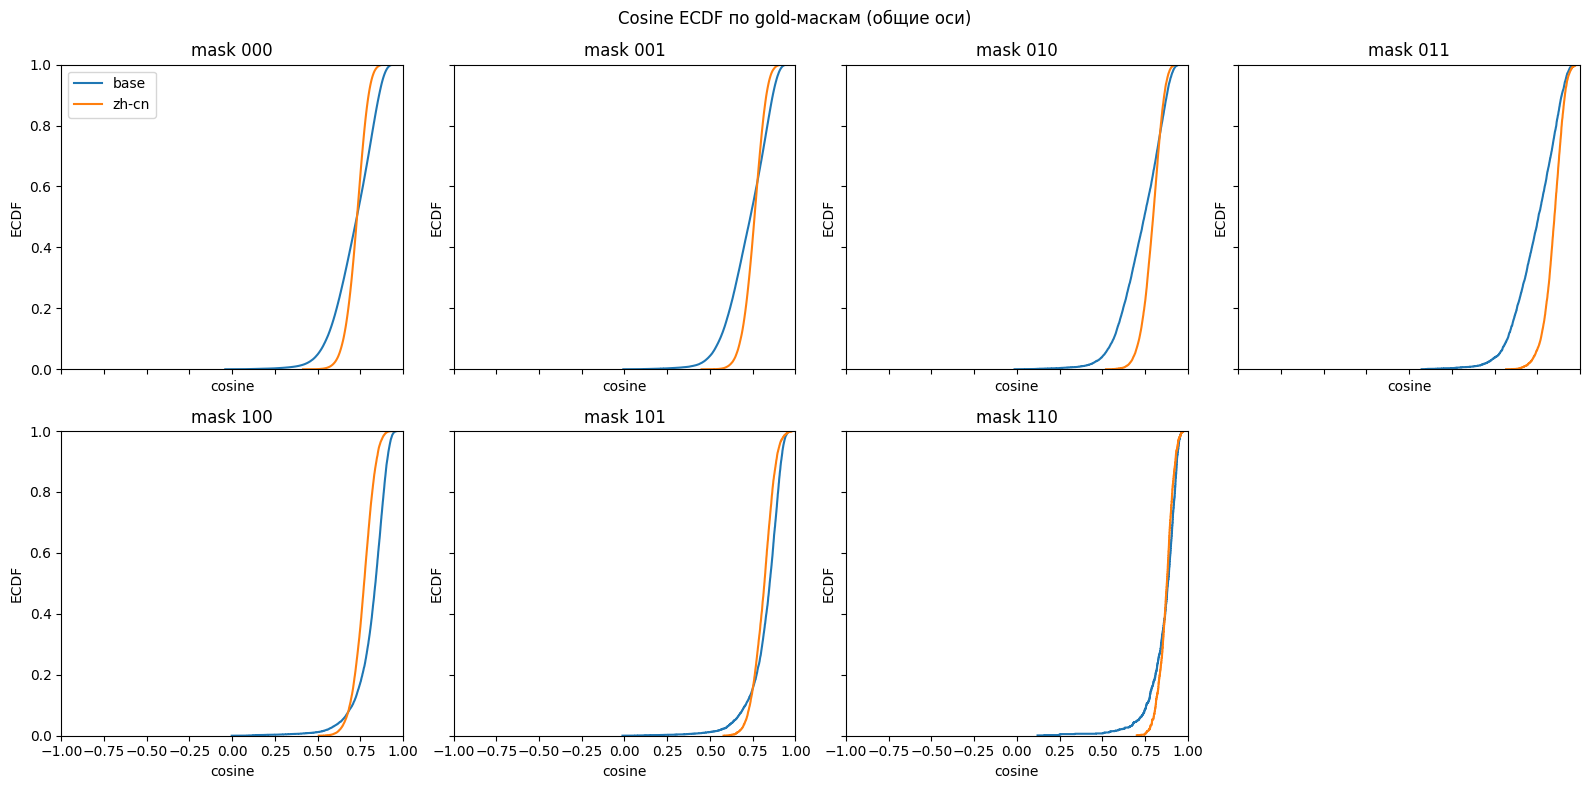

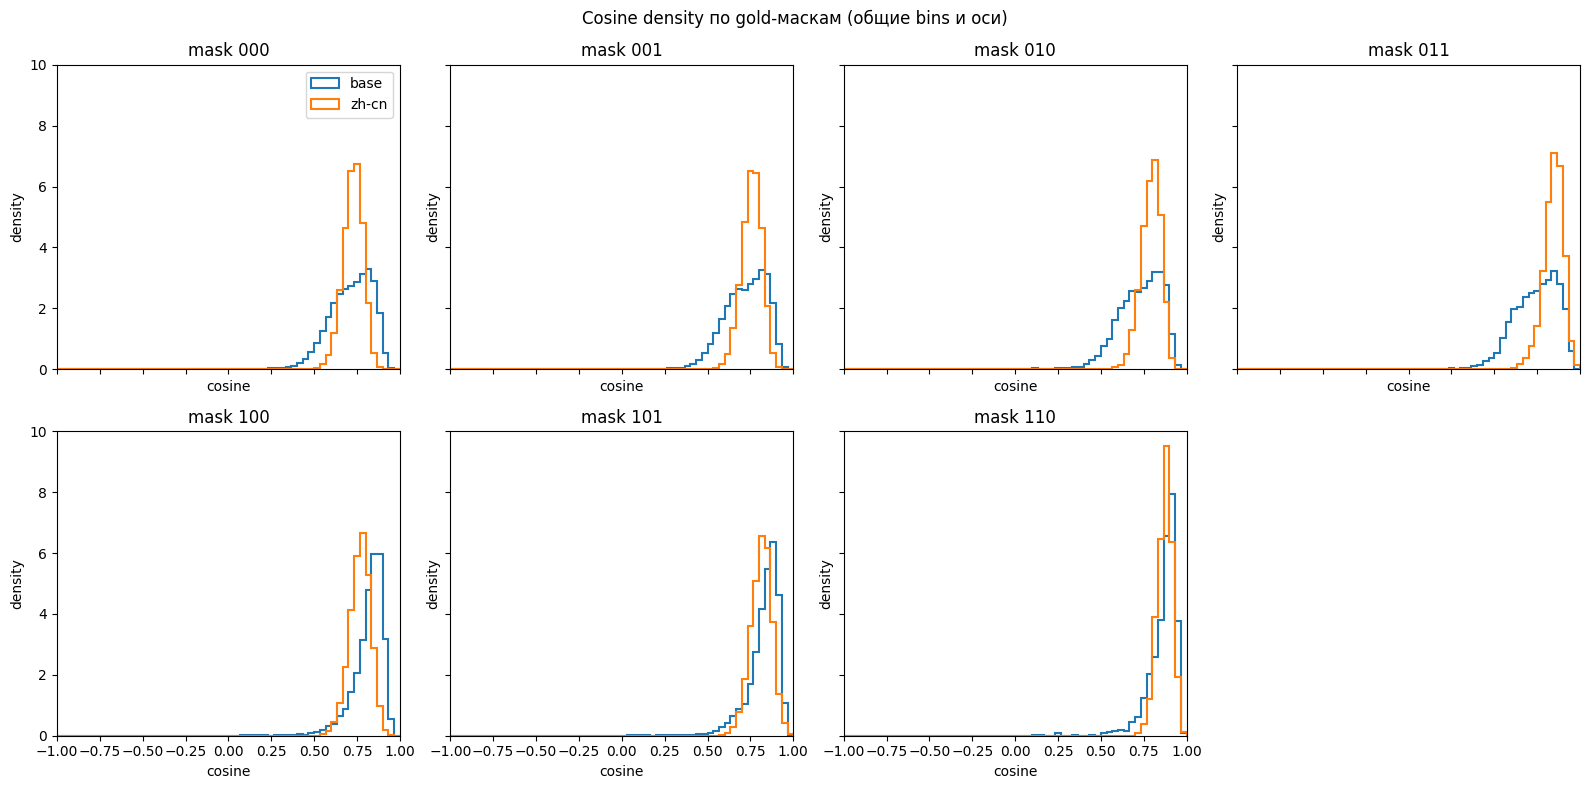

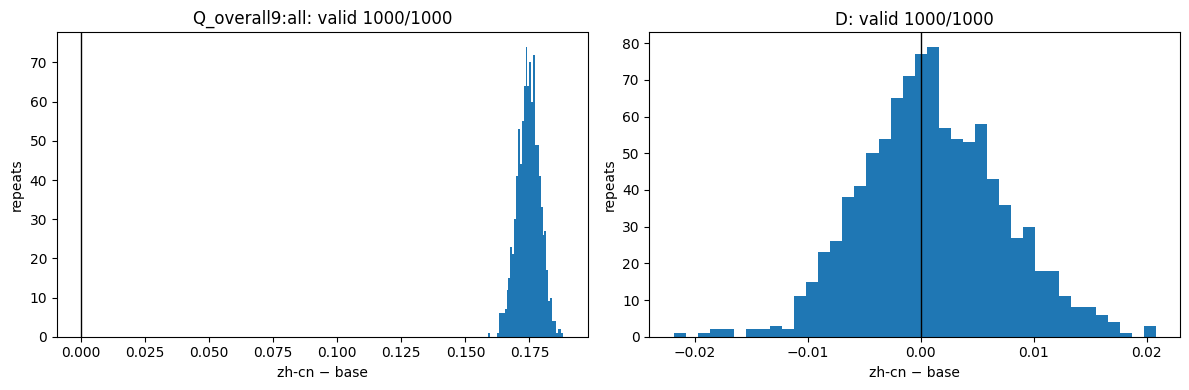

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
for ax, mask in zip(axes.flat, MASK_ORDER):
    for model in MODEL_ORDER:
        values = np.sort(pair_cosine[model][pair_masks == mask])
        ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", label=model)
    ax.set(title=f"mask {mask}", xlabel="cosine", ylabel="ECDF", xlim=(-1, 1), ylim=(0, 1))
axes.flat[-1].axis("off")
axes.flat[0].legend()
fig.suptitle("Cosine ECDF по gold-маскам (общие оси)")
fig.tight_layout()

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
common_bins = np.linspace(-1, 1, 61)
for ax, mask in zip(axes.flat, MASK_ORDER):
    for model in MODEL_ORDER:
        ax.hist(pair_cosine[model][pair_masks == mask], bins=common_bins, density=True,
                histtype="step", linewidth=1.5, label=model)
    ax.set(title=f"mask {mask}", xlabel="cosine", ylabel="density", xlim=(-1, 1))
axes.flat[-1].axis("off")
axes.flat[0].legend()
fig.suptitle("Cosine density по gold-маскам (общие bins и оси)")
fig.tight_layout()

plot_metrics = ["Q_overall9:all", "D"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, plot_metrics):
    family = "Q" if metric.startswith("Q_") else "gap"
    values = bootstrap_replicates[(bootstrap_replicates.family == family) &
                                  (bootstrap_replicates.metric == metric) &
                                  (bootstrap_replicates.model == "delta_zh_minus_base")].value.dropna()
    ax.hist(values, bins=40)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(title=f"{metric}: valid {len(values)}/{BOOTSTRAP_REPEATS}", xlabel="zh-cn − base", ylabel="repeats")
fig.tight_layout()


## Опциональный экспорт

Экспорт выключен по умолчанию. При включении создаётся новый уникальный каталог; существующий путь и любой каталог внутри входных bundles запрещены. Экспортируются компактные metrics, все bootstrap replicates и provenance с input hashes, schema/source metadata, конфигурацией и отсортированными labels.

In [ ]:
def ensure_safe_new_output(root, input_roots):
    root = Path(root).resolve()
    for input_root in input_roots:
        input_root = Path(input_root).resolve()
        if root == input_root or input_root in root.parents:
            raise ValueError(f"Output must not be inside an input bundle: {root}")
    if root.exists():
        raise FileExistsError(f"Refusing to overwrite existing output: {root}")
    root.mkdir(parents=True, exist_ok=False)
    return root


if EXPORT_RESULTS:
    run_name = f"seed-{BOOTSTRAP_SEED}-b-{BOOTSTRAP_REPEATS}-eval-{evaluation['manifest_sha256'][:12]}"
    output_dir = ensure_safe_new_output(
        EXPORT_ROOT / run_name, [BASE_ROOT, ZH_CN_ROOT, evaluation["root"]]
    )
    q_report.to_csv(output_dir / "q_metrics.csv", index=False)
    gap_report.to_csv(output_dir / "gap_metrics.csv", index=False)
    mask_summary.to_csv(output_dir / "mask_summary.csv", index=False)
    bootstrap_replicates.to_csv(output_dir / "bootstrap_replicates.csv", index=False)
    bootstrap_coverage.to_csv(output_dir / "bootstrap_coverage.csv", index=False)
    provenance = {
        "status": "executed_export", "python": platform.python_version(),
        "bootstrap": {"seed": BOOTSTRAP_SEED, "repeats": BOOTSTRAP_REPEATS},
        "population": {"labels_sorted": labels, **coverage},
        "contracts": contracts, "contract_flags": contract_flags,
        "evaluation": {"root": str(evaluation["root"]),
                       "manifest_sha256": evaluation["manifest_sha256"],
                       "schema_version": evaluation["manifest"].get("schema_version"),
                       "evaluation_id": evaluation["manifest"].get("evaluation_id"),
                       "pairing_policy": evaluation["manifest"].get("pairing_policy"),
                       "source_experiment": evaluation["manifest"].get("source_experiment"),
                       "metric": evaluation["manifest"].get("metric"),
                       "artifact_sha256": evaluation["artifact_sha256"]},
        "embeddings": {name: {"root": str(bundle["root"]),
                                "manifest_sha256": bundle["manifest_sha256"],
                                "artifact_sha256": bundle["artifact_sha256"],
                                "model": bundle["manifest"].get("model"),
                                "dimension": bundle["dimension"]}
                       for name, bundle in bundles.items()},
        "edge_specs": EDGE_SPECS, "mask_order": MASK_ORDER,
    }
    with (output_dir / "provenance.json").open("x", encoding="utf-8") as stream:
        json.dump(provenance, stream, ensure_ascii=False, indent=2)
    with (output_dir / "metrics.json").open("x", encoding="utf-8") as stream:
        json.dump({"q": q_report.to_dict("records"), "gaps": gap_report.to_dict("records"),
                   "masks": mask_summary.to_dict("records")}, stream, ensure_ascii=False, indent=2)


## Как интерпретировать будущий запуск

- Сначала проверить provenance, contract flags, coverage, missing/extras и отличие stored pair plan от полного `n(n−1)/2` набора. Основной анализ всегда использует полный набор eligible пар.
- Gold `initial/final/tone` используется буквально: notebook не перепарсивает и не переписывает `u/ü/v`, `gu/qu` или нейтральный тон. Отсутствующий в schema 2 явный `pinyin_contract` фиксируется как ограничение; источник gold-разметки читается из evaluation provenance.
- `Q>0.5` означает, что для данного gold-перехода более совпадающий кандидат чаще имеет больший cosine. `Q=0.80` и `delta Q=0.05` — лишь условные авторские ориентиры для чтения таблицы, не нормы литературы и не фильтры отчёта.
- Главный macro-Q допустим только при наличии всех девяти edges. Пропавшие в bootstrap группы остаются invalid/NaN; `n_valid` обязателен рядом с интервалом.
- `share_positive_sign_stability` — доля парных bootstrap-разностей выше нуля, не p-value.
- `D=mean(110)-mean(000)` задан заранее. Маска 110 не гарантированно максимальна и не проверяет сохранение тона. `D101` — дополнительный срез; observed extrema только описательны.
- Межмодельная разность сырых cosine/gaps зависит от абсолютной геометрии checkpoints. Q отвечает на более устойчивый вопрос о порядке, но также не доказывает причинный эффект языка обучения.
- Интервалы описывают чувствительность к составу этих syllables. Они не охватывают новых speakers, recordings, corpora, training seeds или checkpoints.

Чек-лист запуска: (1) пересоздать evaluation schema 2; (2) вручную задать точный root и manifest SHA; (3) запустить сверху вниз в совместимом окружении NumPy/pickle; (4) прочитать contract flags и coverage до метрик; (5) проверить valid repeats; (6) только затем при необходимости включить уникальный export path.